# Chapter 12: SciPy essentials

NumPy gives you fast arrays and pandas gives you labelled tables. **SciPy** sits on top of NumPy and adds ready-made scientific tools: probability distributions, statistical tests, optimisers, interpolation and integration. Instead of coding a t-test or a curve fit by hand, you call one tested function.

By the end of this chapter you will be able to work with common probability distributions, put a confidence interval around a mean, run and read three classic hypothesis tests on the Brew & Byte data, find the best price on a demand curve, and fill gaps between measurements. It builds on NumPy (Chapters 1–4), grouping and merging (Chapter 8) and plotting (Chapter 10).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, interpolate, integrate

print("SciPy version:", scipy.__version__)
rng = np.random.default_rng(42)

SciPy version: 1.18.1


We will reuse one table many times: revenue per store per day, joined with that day's weather. You saw how to build tables like this in Chapter 8 (grouping and merging) and Chapter 9 (dates).

In [2]:
orders = pd.read_csv("data/orders.csv", parse_dates=["timestamp"])
stores = pd.read_csv("data/stores.csv")
weather = pd.read_csv("data/weather.csv", parse_dates=["date"])

orders["line_total"] = orders["qty"] * orders["unit_price"]
orders["date"] = orders["timestamp"].dt.normalize()

daily = (orders.groupby(["store_id", "date"])
         .agg(revenue=("line_total", "sum"), n_orders=("order_id", "nunique"))
         .reset_index()
         .merge(stores[["store_id", "city"]], on="store_id")
         .merge(weather, on=["date", "city"]))
print(daily.shape)
daily.head(3)

(1464, 7)


,store_id,date,revenue,n_orders,city,temp_c,rain_mm
0,S1,2024-01-01,6650,22,Pune,23.4,0.0
1,S1,2024-01-02,6040,18,Pune,19.7,0.0
2,S1,2024-01-03,5940,25,Pune,23.7,0.0


Each row is one store on one day: 4 stores x 366 days (2024 is a leap year).

## 12.1 What SciPy adds on top of NumPy

NumPy can compute a mean or a standard deviation, but it does not know what a "normal distribution" is or how to test whether two groups differ. SciPy is organised into submodules, each a toolbox for one job. You import the submodule you need.

| Submodule | What it does | Used in |
|---|---|---|
| `scipy.stats` | distributions, summary statistics, hypothesis tests, correlation | 12.2–12.6 |
| `scipy.optimize` | find the minimum of a function, fit curves to data | 12.7 |
| `scipy.interpolate` | estimate values between known points | 12.8 |
| `scipy.integrate` | area under a curve | 12.8 |
| `scipy.linalg`, `scipy.signal`, `scipy.sparse` | advanced linear algebra, signal processing, sparse matrices | not covered here |

Everything in SciPy accepts NumPy arrays and pandas Series, and returns NumPy arrays or small result objects. So what you learned in Chapters 1–9 carries over directly.

## 12.2 Probability distributions

A **distribution** describes how likely each value is. `scipy.stats` has more than a hundred of them, and they all share the same methods, so learning one teaches you all:

| Method | Question it answers |
|---|---|
| `pdf(x)` / `pmf(k)` | how likely is this exact value? (pdf for continuous values, pmf for counts) |
| `cdf(x)` | what is the chance of getting a value **up to** x? |
| `ppf(q)` | the reverse of `cdf`: which value has a fraction q below it? |
| `rvs(size=...)` | draw random samples |

### Normal: bill amounts

Suppose order values at a store are roughly normal with mean 270 and standard deviation 60 (rupees). You create a "frozen" distribution once and then ask it questions.

In [3]:
bill = stats.norm(loc=270, scale=60)   # loc = mean, scale = standard deviation

print(f"P(bill <= 300)  = {bill.cdf(300):.3f}")
print(f"P(bill > 400)   = {1 - bill.cdf(400):.3f}")   # or bill.sf(400)
print(f"90th percentile = {bill.ppf(0.90):.0f}")
print("5 random bills:", bill.rvs(size=5, random_state=rng).round())

P(bill <= 300)  = 0.691
P(bill > 400)   = 0.015
90th percentile = 347
5 random bills: [288. 208. 315. 326. 153.]


About 69% of bills are 300 or less, very few exceed 400, and 90% of bills are below about 347. Note `random_state=rng`: SciPy accepts the NumPy generator from the setup cell, so the samples are reproducible.

### Binomial: how many customers use a loyalty card?

The **binomial** distribution counts successes in a fixed number of yes/no trials. In our data about 55% of orders come from loyalty-card customers. Out of the next 10 orders, how many will be loyalty orders?

P(exactly 5) = 0.234
P(at most 3) = 0.102


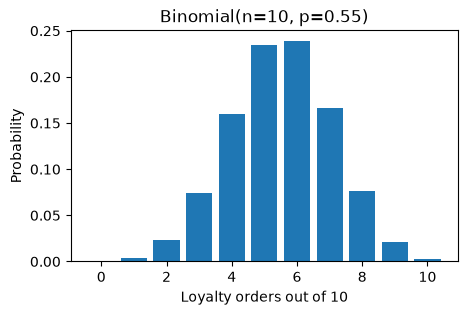

In [4]:
cards = stats.binom(n=10, p=0.55)
k = np.arange(11)

print(f"P(exactly 5) = {cards.pmf(5):.3f}")
print(f"P(at most 3) = {cards.cdf(3):.3f}")

plt.figure(figsize=(5, 3))
plt.bar(k, cards.pmf(k))
plt.xlabel("Loyalty orders out of 10")
plt.ylabel("Probability")
plt.title("Binomial(n=10, p=0.55)")
plt.show()

The most likely outcomes are 5 and 6, and seeing 3 or fewer is fairly rare (about a 10% chance).

### Poisson: orders per day

The **Poisson** distribution models counts of independent events in a fixed time, like orders arriving at a shop. It has a single parameter, the average rate. Let's compare it with the real daily order counts at store S2.

In [5]:
s2 = daily.loc[daily["store_id"] == "S2", "n_orders"]
lam = s2.mean()
model = stats.poisson(mu=lam)

print(f"average orders per day at S2: {lam:.1f}")
print(f"model says P(fewer than 10 orders) = {model.cdf(9):.4f}")
print(f"real share of days with fewer than 10: {(s2 < 10).mean():.4f}")

average orders per day at S2: 15.7
model says P(fewer than 10 orders) = 0.0511
real share of days with fewer than 10: 0.0874


The model and the data broadly agree, but the real data has more quiet days than a plain Poisson predicts, because rain and weekdays change the rate from day to day. A model is a simplification; always compare it with the data.

## 12.3 Describing a sample and a confidence interval

`stats.describe` gives the main summary numbers in one call. **Skewness** measures lopsidedness (0 means symmetric) and **kurtosis** measures how heavy the tails are (0 means "like a normal distribution" in SciPy's default).

In [6]:
s1_rev = daily.loc[daily["store_id"] == "S1", "revenue"]
print(stats.describe(s1_rev))

DescribeResult(nobs=np.int64(366), minmax=(np.int64(2590), np.int64(13590)), mean=np.float64(6885.792349726776), variance=np.float64(3493456.21977693), skewness=np.float64(0.5628162516519111), kurtosis=np.float64(0.48725635324055583))


The sample mean is our best single guess for the "true" average daily revenue at S1, but it would wobble if we had observed a different year. A **confidence interval** puts a range around it. The recipe for a mean uses the t distribution and the **standard error** (`stats.sem`, the standard deviation divided by the square root of n).

In [7]:
mean = s1_rev.mean()
sem = stats.sem(s1_rev)
low, high = stats.t.interval(0.95, df=len(s1_rev) - 1, loc=mean, scale=sem)
print(f"mean daily revenue at S1: {mean:.0f}, 95% CI: {low:.0f} to {high:.0f}")

mean daily revenue at S1: 6886, 95% CI: 6694 to 7078


How to read it: if we repeated the whole year many times and built an interval each time, about 95% of those intervals would contain the true mean. It is **not** a range that holds 95% of individual days; single days vary much more (look at `minmax` above).

Let's check that claim with a quick simulation. We draw many small samples from a known normal distribution and count how often the interval catches the true mean.

In [8]:
true_mean, hits = 100, 0
for _ in range(2000):
    sample = rng.normal(true_mean, 15, size=20)
    lo, hi = stats.t.interval(0.95, df=19, loc=sample.mean(), scale=stats.sem(sample))
    hits += lo <= true_mean <= hi
print(f"intervals containing the true mean: {hits / 2000:.1%}")

intervals containing the true mean: 95.4%


Very close to 95%, as promised.

## 12.4 Hypothesis tests and the p-value

A **hypothesis test** asks: "could the pattern I see be just luck?" You start with a boring assumption, the **null hypothesis** (for example "rain makes no difference to revenue"). Then you ask how surprising your data would be if that assumption were true. That surprise level is the **p-value**: the probability of seeing a difference at least this big **if the null hypothesis were true**.

A small p-value (people often use 0.05 as the cut-off) means the data would be unusual under the boring assumption, so you have evidence against it.

### The idea, by shuffling

At store S1, are heavy-rain days (more than 10 mm) different from the rest? First, the observed difference:

In [9]:
s1 = daily[daily["store_id"] == "S1"].copy()
s1["rainy"] = s1["rain_mm"] > 10

rainy_rev = s1.loc[s1["rainy"], "revenue"].to_numpy()
dry_rev = s1.loc[~s1["rainy"], "revenue"].to_numpy()
observed = rainy_rev.mean() - dry_rev.mean()
print(f"{len(rainy_rev)} rainy days, {len(dry_rev)} other days")
print(f"rainy minus dry: {observed:.0f} rupees per day")

61 rainy days, 305 other days
rainy minus dry: -1332 rupees per day


If rain truly did not matter, the "rainy" labels would be arbitrary. So we shuffle the labels many times and see how often a random split produces a gap as big as the real one. This is a **permutation test**, and it is the p-value idea in pure NumPy.

In [10]:
all_rev = s1["revenue"].to_numpy()
n_rainy = len(rainy_rev)
gaps = []
for _ in range(5000):
    shuffled = rng.permutation(all_rev)
    gaps.append(shuffled[:n_rainy].mean() - shuffled[n_rainy:].mean())
gaps = np.array(gaps)

p_perm = np.mean(np.abs(gaps) >= abs(observed))
print(f"shuffles with a gap at least as big: {p_perm:.4f}")

shuffles with a gap at least as big: 0.0000


Not one shuffle (or almost none) came close to the real gap: luck alone hardly ever produces it.

### The same question with `ttest_ind`

The **t-test** answers the same question with a formula instead of shuffling. `stats.ttest_ind` compares the means of two independent groups. Pass `equal_var=False` (Welch's t-test), which does not assume both groups have the same spread; it is the safer default.

In [11]:
result = stats.ttest_ind(rainy_rev, dry_rev, equal_var=False)
print(f"t = {result.statistic:.2f}, p-value = {result.pvalue:.2e}")
print(f"rainy days earn {-observed / dry_rev.mean():.0%} less than other days")

t = -5.94, p-value = 4.45e-08
rainy days earn 19% less than other days


The p-value is far below 0.05 and the t statistic is negative: heavy-rain days bring clearly less revenue at S1, close to a fifth less. The t statistic is the gap measured in standard errors; the further from 0, the stronger the evidence.

### What a p-value is not

| Common reading | Why it is wrong |
|---|---|
| "p = 0.03 means a 3% chance the null hypothesis is true" | The p-value assumes the null is true; it is about the data, not about the hypothesis. |
| "p > 0.05 proves there is no effect" | It only means you did not find enough evidence. The effect may be small or the sample too small. |
| "A tiny p-value means a big effect" | With lots of data, even a tiny, useless difference gets a tiny p-value. Always report the size of the effect too. |
| "p < 0.05 means the result is important" | Statistical significance is not business importance. A 2-rupee difference can be "significant". |

## 12.5 Chi-square test: are two categories related?

The t-test compares numbers. For two **categorical** columns, such as store and payment method, you count how often each combination happens (a contingency table, `pd.crosstab`, see Chapter 8) and use the **chi-square test of independence**. Its null hypothesis is "payment method does not depend on store".

In [12]:
table = pd.crosstab(orders["store_id"], orders["payment"])
print(table)

payment   Card  Cash    UPI
store_id                   
S1        3391  2092   8496
S2        2189  1296   5140
S3        4713  2921  11582
S4        2881  1767   6735


`chi2_contingency` works out what the counts would look like if the two columns were unrelated (the "expected" counts) and measures how far the real counts are from them.

In [13]:
res = stats.chi2_contingency(table)
print(f"chi2 = {res.statistic:.1f}, dof = {res.dof}, p-value = {res.pvalue:.3f}")

expected = pd.DataFrame(res.expected_freq, index=table.index, columns=table.columns)
print((table / expected).round(3))   # observed / expected, 1.0 = exactly as expected

chi2 = 9.2, dof = 6, p-value = 0.163
payment    Card   Cash    UPI
store_id                     
S1        0.980  0.986  1.012
S2        1.025  0.990  0.992
S3        0.990  1.001  1.004
S4        1.022  1.023  0.985


The p-value is well above 0.05, and every observed count is within a few percent of its expected value. There is no evidence that customers at different stores prefer different payment methods; the share of UPI, card and cash looks the same everywhere. A "no evidence" result like this is useful too: one payment strategy can serve all four stores.

## 12.6 Correlation: does heat sell Cold Brew?

**Correlation** measures how strongly two numeric columns move together, on a scale from -1 (perfect opposite) through 0 (no straight-line link) to +1 (perfect together).

- `stats.pearsonr` measures a **straight-line** relationship and is sensitive to outliers.
- `stats.spearmanr` works on ranks, so it catches any relationship that keeps going up (or down), and it is robust to outliers.

Both return the coefficient and a p-value for the null hypothesis "no correlation". Let's count Cold Brew cups per store per day and compare with temperature at the Mumbai store, S3.

In [14]:
cold = (orders[orders["item"] == "Cold Brew"]
        .groupby(["store_id", "date"])["qty"].sum()
        .rename("cold_brew").reset_index())
daily = daily.merge(cold, on=["store_id", "date"], how="left").fillna({"cold_brew": 0})

s3 = daily[daily["store_id"] == "S3"]
r, p = stats.pearsonr(s3["temp_c"], s3["cold_brew"])
rho, p_s = stats.spearmanr(s3["temp_c"], s3["cold_brew"])
print(f"Pearson r = {r:.2f} (p = {p:.1e})")
print(f"Spearman rho = {rho:.2f} (p = {p_s:.1e})")

Pearson r = 0.55 (p = 4.2e-30)
Spearman rho = 0.55 (p = 1.4e-30)


Both coefficients are clearly positive with tiny p-values: hotter days at S3 sell more Cold Brew. A scatter plot shows the shape of the relationship, which a single number cannot.

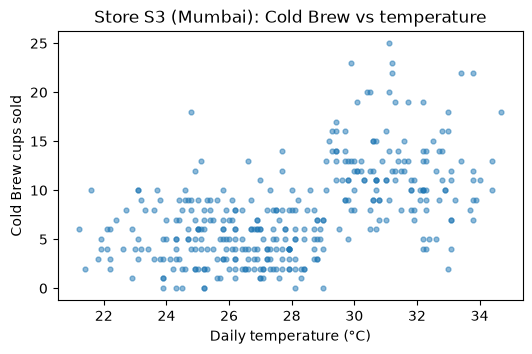

In [15]:
plt.figure(figsize=(6, 3.5))
plt.scatter(s3["temp_c"], s3["cold_brew"], s=12, alpha=0.5)
plt.xlabel("Daily temperature (°C)")
plt.ylabel("Cold Brew cups sold")
plt.title("Store S3 (Mumbai): Cold Brew vs temperature")
plt.show()

The cloud is flat below about 29 °C and jumps up above it. That is a threshold, not a straight line, which is why it is worth looking at the plot and not only at r. And remember: correlation alone does not prove that heat **causes** the sales. Here it is plausible, but in general a third factor (season, a promotion) could drive both.

## 12.7 Optimisation: the best price and fitting a curve

`scipy.optimize` finds the input that makes a function as small as possible. To **maximise** something, minimise its negative.

### Fitting a demand curve with `curve_fit`

Imagine Brew & Byte tried different Cold Brew prices in a test and recorded daily cups sold. Demand drops as price rises. A common model is `cups = a * exp(-b * price)`. `curve_fit` finds the `a` and `b` that best match the data.

In [16]:
prices = np.array([140, 160, 180, 200, 220, 240, 260])
cups = 120 * np.exp(-0.009 * prices) + rng.normal(0, 1.0, prices.size)   # simulated test

def demand(price, a, b):
    return a * np.exp(-b * price)

(a_hat, b_hat), _ = optimize.curve_fit(demand, prices, cups, p0=[100, 0.01])
print(f"fitted a = {a_hat:.1f}, b = {b_hat:.4f}")
print("cups observed:", cups.round(1))

fitted a = 116.1, b = 0.0088
cups observed: [33.7 28.5 24.  18.7 16.  14.9 11.9]


`p0` is a starting guess; curve fitting works by improving a guess step by step, so a sensible start helps. The fitted values land close to the true 120 and 0.009 we used to simulate the data.

### Finding the best price with `minimize_scalar`

Each cup costs about 60 rupees to make. Profit per day is `(price - 60) * cups(price)`. We want the price that maximises it, so we minimise minus the profit, searching between 100 and 400.

In [17]:
def neg_profit(price):
    return -(price - 60) * demand(price, a_hat, b_hat)

best = optimize.minimize_scalar(neg_profit, bounds=(100, 400), method="bounded")
print(f"best price: {best.x:.0f} rupees, profit per day: {-best.fun:.0f}")
print(f"profit at the current 200: {-neg_profit(200):.0f}")

best price: 173 rupees, profit per day: 2845
profit at the current 200: 2777


Let's draw the profit curve to see what the optimiser found.

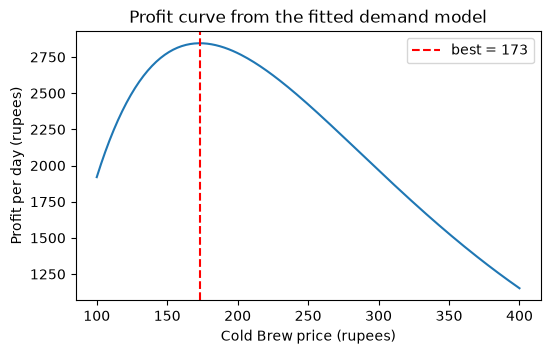

In [18]:
grid = np.linspace(100, 400, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(grid, -neg_profit(grid))
plt.axvline(best.x, color="red", linestyle="--", label=f"best = {best.x:.0f}")
plt.xlabel("Cold Brew price (rupees)")
plt.ylabel("Profit per day (rupees)")
plt.title("Profit curve from the fitted demand model")
plt.legend()
plt.show()

The curve rises, peaks and falls: too cheap and each cup earns little, too expensive and nobody buys. For this model the peak is at 60 + 1/b, and the optimiser lands right on it. For functions of several inputs, use `optimize.minimize` instead, which works the same way with a starting point.

## 12.8 Interpolation and integration (briefly)

### Interpolation: filling in between measurements

A thermometer at S3 logs the temperature every three hours. What was it at 10:30? **Interpolation** estimates values between known points. Linear interpolation joins the dots with straight lines; a **spline** draws a smooth curve through them.

In [19]:
hours = np.array([6, 9, 12, 15, 18, 21])
temps = np.array([25.0, 28.5, 32.0, 33.0, 30.5, 27.0])

linear = interpolate.interp1d(hours, temps)              # straight lines
smooth = interpolate.make_interp_spline(hours, temps, k=3)  # cubic spline

print(f"10:30 linear: {linear(10.5):.2f} °C, spline: {smooth(10.5):.2f} °C")

10:30 linear: 30.25 °C, spline: 30.42 °C


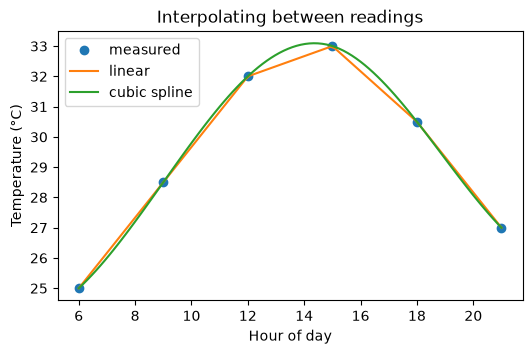

In [20]:
fine = np.linspace(6, 21, 100)
plt.figure(figsize=(6, 3.5))
plt.plot(hours, temps, "o", label="measured")
plt.plot(fine, linear(fine), label="linear")
plt.plot(fine, smooth(fine), label="cubic spline")
plt.xlabel("Hour of day")
plt.ylabel("Temperature (°C)")
plt.title("Interpolating between readings")
plt.legend()
plt.show()

The spline is smoother and usually closer to reality for physical quantities. Both only work **between** the first and last points: guessing beyond them (extrapolation) is risky. For simple straight-line filling, `np.interp` does the same job as `interp1d`, and newer SciPy code tends to prefer `make_interp_spline`.

### Integration: area under a curve

`integrate.quad` computes the area under a function between two limits. Two quick uses: the probability of landing within one standard deviation of a normal mean, and the expected number of customers from an arrival-rate curve.

In [21]:
area, err = integrate.quad(stats.norm.pdf, -1, 1)
print(f"P(-1 < Z < 1) = {area:.4f}  (same as {stats.norm.cdf(1) - stats.norm.cdf(-1):.4f})")

def arrivals_per_hour(t):          # a smooth morning peak at 9:00
    return 5 + 20 * np.exp(-((t - 9) ** 2) / 2)

total, _ = integrate.quad(arrivals_per_hour, 7, 12)
print(f"expected customers from 7:00 to 12:00: {total:.0f}")

P(-1 < Z < 1) = 0.6827  (same as 0.6827)
expected customers from 7:00 to 12:00: 74


`quad` returns two numbers: the answer and an estimate of its error, which is tiny here. The first line confirms the familiar rule that about 68% of a normal distribution lies within one standard deviation of the mean.

## 12.9 Common mistakes

| Mistake | What happens | Fix |
|---|---|---|
| Reading p = 0.03 as "3% chance the null is true" | You overstate the evidence | Say "data this extreme would be rare if there were no effect" |
| Treating p > 0.05 as proof of no effect | You may miss a real but small effect | Say "no evidence of a difference" and look at the effect size and sample size |
| Using `ttest_ind` with the default `equal_var=True` on groups of different spread and size | p-value can be misleading | Use `equal_var=False` (Welch's t-test) |
| Passing raw rows instead of a count table to `chi2_contingency` | Error or meaningless result | Build the table with `pd.crosstab` first |
| Trusting r without a plot | A threshold, curve or outlier is hidden | Always draw a scatter plot; try `spearmanr` too |
| Using `minimize_scalar` to maximise | You find the lowest point, not the highest | Minimise the negative of your function |

## 12.10 Cheat sheet

| Task | Code |
|---|---|
| Normal distribution | `d = stats.norm(loc=270, scale=60)` |
| Probability up to x / percentile | `d.cdf(x)`, `d.ppf(0.9)` |
| Exact-count probability | `stats.binom(n, p).pmf(k)`, `stats.poisson(mu).pmf(k)` |
| Random samples | `d.rvs(size=100, random_state=rng)` |
| Summary of a sample | `stats.describe(x)` |
| 95% CI for a mean | `stats.t.interval(0.95, df=n-1, loc=x.mean(), scale=stats.sem(x))` |
| Compare two means | `stats.ttest_ind(a, b, equal_var=False)` |
| Two categorical columns | `stats.chi2_contingency(pd.crosstab(df.a, df.b))` |
| Correlation | `stats.pearsonr(x, y)`, `stats.spearmanr(x, y)` |
| Fit a curve | `params, _ = optimize.curve_fit(f, x, y, p0=[...])` |
| Minimise one variable | `optimize.minimize_scalar(f, bounds=(lo, hi), method="bounded")` |
| Interpolate | `interpolate.make_interp_spline(x, y, k=3)(new_x)` |
| Area under a curve | `integrate.quad(f, a, b)` |

## 12.11 Exercises

**1.** A store gets on average 25 orders per hour at lunch time. Using a Poisson distribution, what is the probability of 35 or more orders in one hour? What count is only exceeded 5% of the time?

In [22]:
# Solution
lunch = stats.poisson(mu=25)
print(f"P(35 or more) = {lunch.sf(34):.4f}")   # sf(k) = P(X > k), so sf(34) = P(X >= 35)
print(f"95th percentile: {lunch.ppf(0.95):.0f} orders")

P(35 or more) = 0.0338
95th percentile: 33 orders


**2.** Compute a 95% confidence interval for the mean daily revenue at store S4. Is the interval wider or narrower than S1's, and why?

In [23]:
# Solution
s4_rev = daily.loc[daily["store_id"] == "S4", "revenue"]
lo4, hi4 = stats.t.interval(0.95, df=len(s4_rev) - 1, loc=s4_rev.mean(), scale=stats.sem(s4_rev))
print(f"S4: mean {s4_rev.mean():.0f}, CI {lo4:.0f} to {hi4:.0f}, width {hi4 - lo4:.0f}")
print(f"S1 width: {high - low:.0f}")

S4: mean 5570, CI 5404 to 5736, width 332
S1 width: 384


Both stores have 366 days, so the width depends on how much daily revenue varies. S4 is a smaller store, so its revenue varies less in rupees and its interval is narrower.

**3.** Are weekend days (Saturday and Sunday) different from weekdays in revenue at store S3? Run a Welch t-test and report the difference in means as well as the p-value.

In [24]:
# Solution
s3 = daily[daily["store_id"] == "S3"]
weekend = s3["date"].dt.day_of_week >= 5
a, b = s3.loc[weekend, "revenue"], s3.loc[~weekend, "revenue"]
res = stats.ttest_ind(a, b, equal_var=False)
print(f"weekend mean {a.mean():.0f}, weekday mean {b.mean():.0f}, p = {res.pvalue:.1e}")

weekend mean 11341, weekday mean 8830, p = 6.5e-15


**4.** Use `chi2_contingency` to test whether the product **category** depends on the **store**. Then look at the observed/expected ratios: is any difference large enough to matter?

In [25]:
# Solution
cat_table = pd.crosstab(orders["store_id"], orders["category"])
res = stats.chi2_contingency(cat_table)
print(f"p-value = {res.pvalue:.3f}")
print((cat_table / res.expected_freq).round(3))

p-value = 0.147
category  Bakery  Coffee   Food    Tea
store_id                              
S1         1.018   0.988  0.999  1.008
S2         0.980   1.001  1.012  1.020
S3         0.999   1.013  1.004  0.963
S4         0.994   0.992  0.986  1.037


Whatever the p-value, ratios close to 1.0 mean each store sells roughly the same mix. Remember the misreading table in 12.4: significance and importance are different things.

**5.** Fit a straight line `cups = m * temp + c` to the S3 Cold Brew data with `curve_fit`. Then use it to predict cups on a 32 °C day. Why might a straight line be a poor model here (look back at the scatter plot in 12.6)?

In [26]:
# Solution
def line(t, m, c):
    return m * t + c

(m_hat, c_hat), _ = optimize.curve_fit(line, s3["temp_c"], s3["cold_brew"])
print(f"slope {m_hat:.2f} cups per °C, intercept {c_hat:.1f}")
print(f"prediction at 32 °C: {line(32, m_hat, c_hat):.1f} cups")

slope 0.84 cups per °C, intercept -15.9
prediction at 32 °C: 11.0 cups


The real data jumps at around 29 °C rather than rising steadily, so a straight line underestimates hot days and overestimates mild ones. In the machine learning stage you will meet models that can learn shapes like this.